# Cirq · 损失分布与 VaR / CVaR

Loss distribution & VaR / CVaR

[金融 Cirq 总目录](cirq_finance.html) · **QuantumBridge 原创金融教学扩展 / Cirq 本地仿真**

两量子比特编码四种损失情景，用经验分布估计预期损失与尾部风险。

合成模型；不是投资建议，不是完整行业支持，也不证明 QuantumBridge 原生替代 Cirq。

## 1. 官方方法与归属 / Sources

Cirq 官方模拟与测量 API 是技术基础；VaR/CVaR 业务逻辑是我们的扩展。这里是直接采样，不是量子振幅估计；没有信用校准、稀有风险认证或完整风控平台。

- [Google Cirq · Simulation](https://quantumai.google/cirq/simulate/simulation)

## 2. 原理与步骤 / Model & workflow

假定损失 $L=(0,1,4,12)$，物理概率 $p=(0.55,0.25,0.15,0.05)$。
用受控 RY 制备 $\sum_j\sqrt{p_j}|j\rangle$，测量得到经验概率。
$VaR_\alpha=\inf\{l:F(l)\ge\alpha\}$；离散 CVaR 使用期望短缺定义
$ES_\alpha=VaR_\alpha+\frac{\sum_jp_j(L_j-VaR_\alpha)^+}{1-\alpha}$，
不能误用 $E[L|L\ge VaR]$。本例 $\alpha=0.85$，精确 EL=1.45、VaR=4、ES=20/3。

定义合成损失与概率 → 条件概率转 RY → 检查振幅平方 → 4096 次本地测量 → 经验 CDF → EL / VaR / ES → DKW 分位不确定区间。

## 3. 运行环境 / Local environment

需要已安装 `cirq`、`numpy`、`matplotlib` 与 Jupyter。代码不依赖本仓库私有模块，可在安装上述依赖的 Python 内核从上到下运行。没有自动安装、联网或密钥读取。

In [1]:
import json, sys
import cirq
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

SEED, SHOTS = 20261101, 4096
simulator = cirq.Simulator(dtype=np.complex128, seed=SEED)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Backend: local cirq.Simulator | Cirq:', cirq.__version__)
print('Python:', sys.version.split()[0], '| hardware jobs: 0')
print('Bit order: q0 first / most significant bit; synthetic data only.')

def probabilities(circuit, qubits):
    state = simulator.simulate(circuit, qubit_order=qubits).final_state_vector
    return np.abs(state)**2

def measured_counts(circuit, qubits, key='out'):
    measured = circuit + cirq.Circuit(cirq.measure(*qubits, key=key))
    histogram = simulator.run(measured, repetitions=SHOTS).histogram(key=key)
    return np.array([histogram.get(i, 0) for i in range(2**len(qubits))], dtype=int)

def compare_plot(labels, exact, sampled, title):
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(8, 3.3), layout='constrained')
    ax.bar(x-.18, exact, .36, label='Exact model', color='#137f76')
    ax.bar(x+.18, sampled, .36, label='4096 local Cirq shots', color='#bc4164')
    ax.set(xticks=x, xticklabels=labels, ylabel='Probability', title=title)
    ax.legend()
    plt.show()

Backend: local cirq.Simulator | Cirq: 1.6.1
Python: 3.12.6 | hardware jobs: 0
Bit order: q0 first / most significant bit; synthetic data only.


## 4. 输入与电路 / Inputs & circuit

In [2]:
qubits = list(cirq.LineQubit.range(2))
p, losses, alpha = np.array([.55,.25,.15,.05]), np.array([0.,1.,4.,12.]), .85

## 5. 中间结果与实际本地采样 / Intermediate & sampled results

图中 Exact 为同一模型的精确分布；Cirq shots 为有限次模拟测量，不是真机回执。

Prepared state probabilities: [0.55 0.25 0.15 0.05]
Circuit:
0: ───Ry(0.295π)───(0)──────────@────────────
                   │            │
1: ────────────────Ry(0.378π)───Ry(0.333π)───


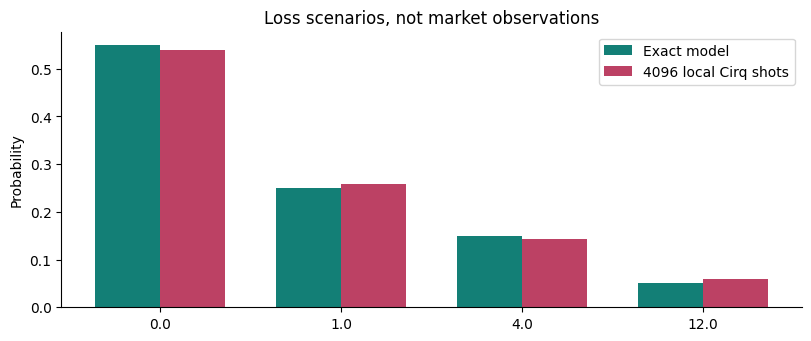

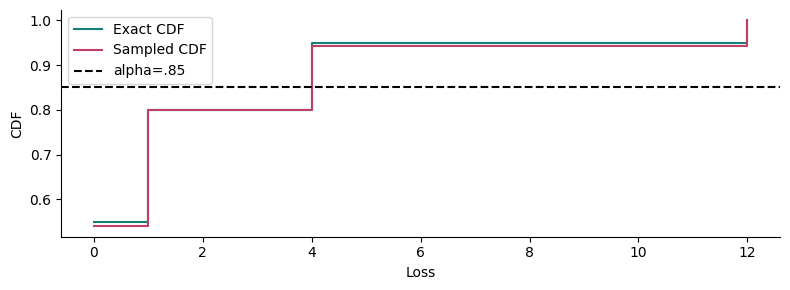

In [3]:
def prepare_four(probabilities, qubits):
    p = np.asarray(probabilities, dtype=float)
    assert p.shape == (4,) and np.all(p > 0) and np.isclose(p.sum(), 1)
    left = p[0] + p[1]
    circuit = cirq.Circuit(cirq.ry(2*np.arccos(np.sqrt(left)))(qubits[0]))
    circuit.append(cirq.ry(2*np.arccos(np.sqrt(p[0]/left)))(qubits[1])
                   .controlled_by(qubits[0], control_values=[0]))
    circuit.append(cirq.ry(2*np.arccos(np.sqrt(p[2]/(1-left))))(qubits[1])
                   .controlled_by(qubits[0], control_values=[1]))
    return circuit

circuit = prepare_four(p, qubits)
exact = probabilities(circuit, qubits)
assert np.allclose(exact, p, atol=1e-12)
print('Prepared state probabilities:', exact)
print('Circuit:', circuit, sep='\n')
counts = measured_counts(circuit, qubits)
empirical = counts/SHOTS
def risk(probability):
    index = int(np.searchsorted(np.cumsum(probability), alpha))
    var = float(losses[index])
    return {'EL': float(probability@losses), 'VaR': var,
            'CVaR_ES': float(var+probability@np.maximum(losses-var, 0)/(1-alpha))}
reference, sampled = risk(p), risk(empirical)
assert np.isclose(reference['EL'], 1.45)
assert reference['VaR'] == 4 and np.isclose(reference['CVaR_ES'], 20/3)
epsilon = float(np.sqrt(np.log(2/.05)/(2*SHOTS)))
quantile = lambda a: float(losses[min(np.searchsorted(np.cumsum(empirical), a), 3)])
var_interval = [quantile(max(0, alpha-epsilon)), quantile(min(1, alpha+epsilon))]
compare_plot([str(v) for v in losses], p, empirical, 'Loss scenarios, not market observations')
plt.figure(figsize=(8,3))
plt.step(losses, np.cumsum(p), where='post', label='Exact CDF', color='#137f76')
plt.step(losses, np.cumsum(empirical), where='post', label='Sampled CDF', color='#bc4164')
plt.axhline(alpha, color='black', ls='--', label='alpha=.85')
plt.xlabel('Loss'); plt.ylabel('CDF'); plt.legend(); plt.tight_layout(); plt.show()
evidence = {'qubits': 2, 'shots': SHOTS, 'counts': counts.tolist(),
            'exact': reference, 'sampled': sampled,
            'var_95pct_DKW_interval': var_interval, 'dkw_epsilon': epsilon,
            'ideal_probability': exact.tolist(),
            'validation': 'Prepared distribution and independent exact EL/VaR/ES checked'}

## 6. 最终输出与边界 / Evidence & limitations

Cirq 官方模拟与测量 API 是技术基础；VaR/CVaR 业务逻辑是我们的扩展。这里是直接采样，不是量子振幅估计；没有信用校准、稀有风险认证或完整风控平台。

本次硬件任务为 0。不同 SDK 版本的随机抽样序列可能不同，解析断言仍应成立。

In [4]:
evidence.update({'backend': 'local cirq.Simulator', 'cirq_version': cirq.__version__, 'python': sys.version.split()[0], 'seed': SEED, 'hardware_jobs': 0})
print('EVIDENCE_JSON=' + json.dumps(evidence, ensure_ascii=False, allow_nan=False))

EVIDENCE_JSON={"qubits": 2, "shots": 4096, "counts": [2211, 1061, 585, 239], "exact": {"EL": 1.4500000000000002, "VaR": 4.0, "CVaR_ES": 6.666666666666666}, "sampled": {"EL": 1.530517578125, "VaR": 4.0, "CVaR_ES": 7.111979166666666}, "var_95pct_DKW_interval": [4.0, 4.0], "dkw_epsilon": 0.02122033618344718, "ideal_probability": [0.55, 0.25, 0.15000000000000005, 0.049999999999999996], "validation": "Prepared distribution and independent exact EL/VaR/ES checked", "backend": "local cirq.Simulator", "cirq_version": "1.6.1", "python": "3.12.6", "seed": 20261101, "hardware_jobs": 0}
